# CCE 3503 - Practical Machine Learning 
## Assignment 1: Feature Analysis
#### Name: Dave Galea
#### Student ID: 0283404L

In [21]:
import pandas as pd
import numpy as np
import scipy as sp
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

## Task 1: Data cleaning, missing data, and normalization (+splitting)

Note: the above task has been modified to include the splitting from task 2 so to avoid data leakage.

In [22]:
raw_data = pd.read_csv("labelled.csv")
raw_data.head(10) # just getting an feel of the data

,id,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,...,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate,performance_score
0,8001,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,...,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9,58.16
1,8002,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,...,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6,84.12
2,8003,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,...,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8,72.94
3,8004,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,...,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5,51.76
4,8005,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,...,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9,58.08
5,8006,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,...,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1,64.86
6,8007,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,...,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6,62.30
7,8008,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,...,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7,57.49
8,8009,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,...,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0,76.93
9,8010,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,...,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4,60.87


### Subtask 1: Remove the non-predictive features and the potential target features from the dataset.

In [23]:
clean_data = raw_data.copy()

# Remove the non predictive features and target features
non_predictive = [
    "id", 
    "laptop_serial_number_last_digit", 
    "parking_bay_number",
    ]
target = [
    "performance_score",
    "manager_discretionary_bonus_count"
    ]

cols_to_remove = non_predictive + target

clean_data = clean_data.drop(columns = cols_to_remove)

clean_data.head(10)


,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,first_pass_yield_rate,...,work_consistency_metric_std,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate
0,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,35.9,...,6.99,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9
1,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,66.9,...,3.66,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6
2,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,56.0,...,5.85,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8
3,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,69.1,...,5.29,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5
4,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,54.1,...,5.38,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9
5,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,72.4,...,5.71,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1
6,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,61.4,...,6.24,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6
7,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,6.4,...,10.00,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7
8,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,61.8,...,5.62,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0
9,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,52.1,...,5.56,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4


#### A short comment on the above: 

##### Non predictive features
| Feature | Reason for removing |
| -------- | ------- |
| Id  |  The ID is unique for every single person, and has no effect on performance   |
| laptop_serial_number_last_digit | The last digit of a serial number is random for every person and has no effect on performance.     |
| parking_bay_number    |  Since we have no information of the parking layout (Some companies have it that certain areas are for different ranking employees), we can treat the number as random and with no  likely effect on performance   |

##### Potential Target Features
| Feature | Reason for removing |
| -------- | ------- |
| performance_score | Target Feature stated in the assignment description (not a potential target feature; just the target feature) |
| manager_discretionary_bonus_count | If bonuses are awarded based on the performance score, then we are using information that we not have access to at prediction time; data leakage. However, if bonuses are awarded before the final performance evaluation, the feature could be a valid predictor. Since the timing is unknown, I chose to exclude this feature so to err on the safer side. 

### Subtask 2: Randomly split the dataset into a train subset and test subset using an appropriate ratio of train subset samples to test subset samples. Comment on the choice of ratio.

In [24]:
X = clean_data # input features
y = raw_data["performance_score"] # target feature

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 4
)

Since we are going to be using wrapping methods, which typically use cross-validation, we use an 80/20 split which is the a common choice for when separate validation set is not used. This leaves 20% of the dataset (1000 rows in this case) left for testing the model at the end. 

### Subtask 3: Use appropriate techniques to handle features with missing data. Comment on why you selected the techniques used for missing data, and any adverse effect they may have on the data.

In [25]:
# First we see how much missing data we have in our dataset 
# how many employees have missing data?

# employees with at least one missing feature
employees_with_missing = (clean_data == "?").any(axis=1).sum()

# employees with no missing features
employees_complete = (~(clean_data == "?").any(axis=1)).sum()

print("Total employees:", len(clean_data))
print("Employees with missing values:", employees_with_missing)
print("Employees with complete data:", employees_complete)


Total employees: 5000
Employees with missing values: 3620
Employees with complete data: 1380


From the above we know that elimination of all rows with a missing value is simply not an option. We can look into which features have the most missing values, and see if one feature is causing the discrepancy. 

In [26]:
# which features have missing data, and how much do they have missing?
missing_count = (clean_data == "?").sum(axis=0)

missing_count = missing_count[missing_count > 0].sort_values(ascending=False)

print(missing_count.to_string())


favourite_music_genre           2107
commute_time_minutes             772
360_feedback_score_avg           746
client_satisfaction_score        500
technical_assessment_score       349
on_time_task_completion_rate     261
age                              261
team_collaboration_rating        196
sex                              194
avg_hours_worked_per_week        149


From the above, I have made the following decisions: 
- favourite_music_genre: remove the feature entirely, its probable effect as a feature was already low, but with such high amount of missing data, imputing nearly half of the feature could significantly distort its original distribution.
- For the rest of the numerical features, I will examine the distributions of each; If it is skewed, i will use the median for imputation as it is less affected by extreme values. If the distribution is approximately symmetric, I will use the mean, as it represents the centre of data well. 
- For Sex, I will 

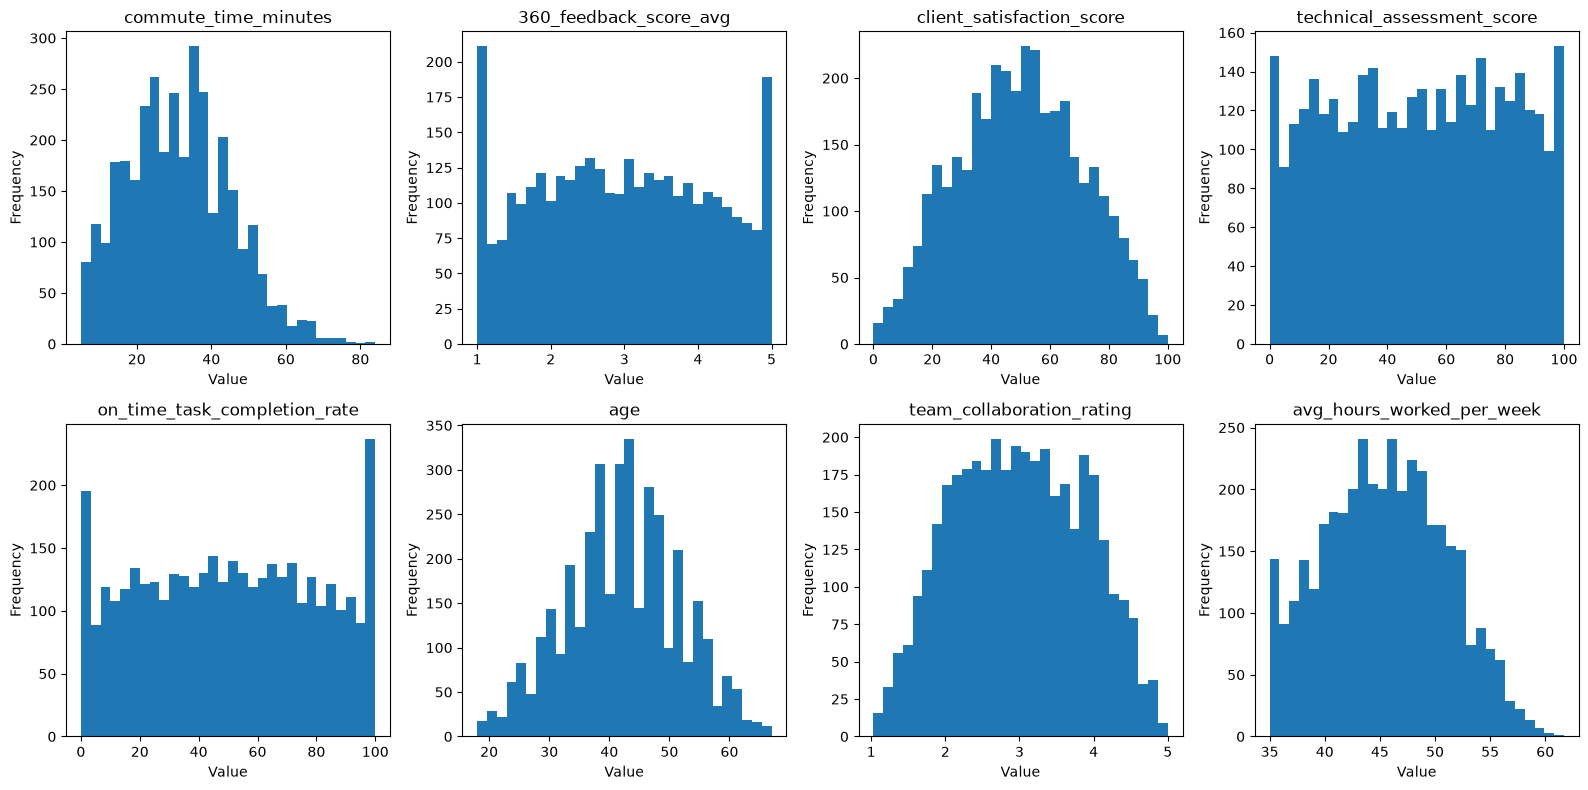

In [28]:
# Numerical features with missing values
numeric_features = [
    "commute_time_minutes",
    "360_feedback_score_avg",
    "client_satisfaction_score",
    "technical_assessment_score",
    "on_time_task_completion_rate",
    "age",
    "team_collaboration_rating",
    "avg_hours_worked_per_week"
]


# Convert missing values to NaN and ensure numerical types
numeric_data = X_train[numeric_features].replace("?", np.nan)
numeric_data = numeric_data.apply(pd.to_numeric)

# Plot the distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for feature, ax in zip(numeric_features, axes.flat):
    ax.hist(numeric_data[feature].dropna(), bins=30)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## Task 2: Filter methods

## Task 3: Wrapper Methods

## Task 4: Feature Projection

## Task 5: Comparison

## Task 6: Prediction on unlabelled samples